Hizkia Marvel Abinaya
23031554061

## 1.1

In [2]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "010504hma")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Koneksi berhasil!")

Koneksi berhasil!


## 1.2

In [ ]:
from neo4j import GraphDatabase, RoutingControl

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


## 1.3

In [6]:
import argparse, os, sys
import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm

In [7]:
def parse_arguments(argv=None):
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument("-u", "--user", default="neo4j",
                        help="Username Neo4j (default: neo4j)")
    parser.add_argument("-p", "--password", default="neo4j",
                        help="Password Neo4J (default: neo4j)")
    parser.add_argument("-b", "--bolt", default="neo4j://127.0.0.1:7687",
                        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)")
    parser.add_argument("-s", "--source", default="data",
                        help="Direktori/folder sumber data (default: data)")
    return parser.parse_args(argv)

# Di notebook, kita kirim argumen sebagai daftar (menggantikan terminal)
args = parse_arguments(["-p", "010504hma"])
print(args)

Namespace(user='neo4j', password='010504hma', bolt='neo4j://127.0.0.1:7687', source='data')


In [8]:
csv_file_path = os.path.join(args.source, "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

print("File ditemukan:", csv_file_path)

File ditemukan: data\events.csv


In [9]:
try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
    print("Koneksi berhasil!")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

Koneksi berhasil!


In [10]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [11]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS "
                "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS "
                "FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

In [13]:
batch_size = 5000
total_rows = 20000   # uji coba; nanti diganti jumlah baris sebenarnya
total_chunks = (total_rows // batch_size)

with driver.session() as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size, nrows=total_rows)

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil.")

Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 4/4 [00:02<00:00,  1.73it/s]

Proses impor berhasil.


## 2.1

1 + 2

Buat kolom baru "datetime" berdasarkan kolom timestamp, menentukan p1 dan p2, hapus kolom "datetime", disimpan ke csv

In [14]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

p1_mulai, p1_akhir = "2015-05-12", "2015-07-12 23:59:59.999"
p2_mulai, p2_akhir = "2015-07-21", "2015-08-05 23:59:59.999"

p1 = df[(df["datetime"] >= p1_mulai) & (df["datetime"] <= p1_akhir)]
p2 = df[(df["datetime"] >= p2_mulai) & (df["datetime"] <= p2_akhir)]

p1.drop(columns="datetime").to_csv("data/events_p1.csv", index=False)
p2.drop(columns="datetime").to_csv("data/events_p2.csv", index=False)

for nama, d in [("P1", p1), ("P2", p2)]:
    print(nama, "| baris:", len(d),
          "| visitor:", d["visitorid"].nunique(),
          "| item:", d["itemid"].nunique())
    print(d["event"].value_counts().to_dict())

P1 | baris: 1294055 | visitor: 658383 | item: 169779
{'view': 1252127, 'addtocart': 31518, 'transaction': 10410}
P2 | baris: 357351 | visitor: 196339 | item: 87110
{'view': 345008, 'addtocart': 9230, 'transaction': 3113}


Import data dari csv ke neo4j

In [ ]:
csv_file_path = os.path.join(args.source, "events_p1.csv")

batch_size = 5000
total_rows = 1294055          # jumlah baris P1 (dari output filter)
total_chunks = (total_rows // batch_size) + 1

with driver.session() as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):

        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil.")

Membaca file data dari: data\events_p1.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 259/259 [01:43<00:00,  2.50it/s]

Proses impor berhasil.


3

cek jumlah node dan relasi

In [16]:
def jalankan(query):
    records, _, _ = driver.execute_query(query, database_="neo4j")
    return records

print("Jumlah simpul per label")
for r in jalankan("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah ORDER BY jumlah DESC"):
    print(r["label"], r["jumlah"])

print("\nJumlah relasi per tipe")
for r in jalankan("MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah ORDER BY jumlah DESC"):
    print(r["tipe"], r["jumlah"])

Jumlah simpul per label
Visitor 658383
Item 169779

Jumlah relasi per tipe
VIEWED 1252127
ADDED_TO_CART 31518
BOUGHT 10410


In [17]:
query = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitor,
       i.itemId    AS item,
       type(r)     AS tipe,
       count(*)    AS n
"""

df_edges = driver.execute_query(
    query,
    database_="neo4j",
    result_transformer_=lambda r: r.to_df()
)

print(df_edges.shape)
print(df_edges.head())
print(df_edges["tipe"].value_counts())

(1034215, 4)
   visitor    item    tipe  n
0   257597  355908  VIEWED  1
1   981382  355908  VIEWED  1
2  1102250  355908  VIEWED  1
3    62710  355908  VIEWED  1
4    76757  355908  VIEWED  1
tipe
VIEWED           995937
ADDED_TO_CART     28396
BOUGHT             9882
Name: count, dtype: int64


Melakukan VSM (Vector Space Modelling)

In [18]:
import numpy as np
from scipy.sparse import csr_matrix

bobot = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
df_edges["bobot"] = df_edges["tipe"].map(bobot)

# Petakan ID asli ke nomor baris/kolom 0,1,2,...
visitor_ids = df_edges["visitor"].astype("category")
item_ids    = df_edges["item"].astype("category")

baris = visitor_ids.cat.codes.to_numpy()
kolom = item_ids.cat.codes.to_numpy()

matriks = csr_matrix(
    (df_edges["bobot"].to_numpy(), (baris, kolom)),
    shape=(len(visitor_ids.cat.categories), len(item_ids.cat.categories))
)

print("Shape:", matriks.shape)
print("Jumlah sel terisi (non-nol):", matriks.nnz)
print("Kepadatan:", matriks.nnz / (matriks.shape[0] * matriks.shape[1]))
print("Nilai terbesar:", matriks.max())

Shape: (658383, 169779)
Jumlah sel terisi (non-nol): 1001127
Kepadatan: 8.95625797648954e-06
Nilai terbesar: 9


4

In [20]:
# Berapa item yang disentuh tiap visitor (jumlah sel non-nol per baris)
item_per_visitor = np.diff(matriks.indptr)

print("VSM Visitor (per baris)")
print("Jumlah vektor      :", matriks.shape[0])
print("Dimensi tiap vektor:", matriks.shape[1], "(satu angka per item)")
print("Rata-rata item/visitor :", item_per_visitor.mean().round(2))
print("Median item/visitor    :", np.median(item_per_visitor))
print("Maksimum item/visitor  :", item_per_visitor.max())
print("Visitor hanya 1 item   :", (item_per_visitor == 1).sum(),
      f"({(item_per_visitor == 1).mean():.1%})")

VSM Visitor (per baris)
Jumlah vektor      : 658383
Dimensi tiap vektor: 169779 (satu angka per item)
Rata-rata item/visitor : 1.52
Median item/visitor    : 1.0
Maksimum item/visitor  : 1492
Visitor hanya 1 item   : 526102 (79.9%)


5

In [21]:
matriks_csc = matriks.tocsc()
visitor_per_item = np.diff(matriks_csc.indptr)

print("VSM Item (per kolom)")
print("Jumlah vektor      :", matriks.shape[1])
print("Dimensi tiap vektor:", matriks.shape[0], "(satu angka per visitor)")
print("Rata-rata visitor/item :", visitor_per_item.mean().round(2))
print("Median visitor/item    :", np.median(visitor_per_item))
print("Maksimum visitor/item  :", visitor_per_item.max())
print("Item hanya 1 visitor   :", (visitor_per_item == 1).sum(),
      f"({(visitor_per_item == 1).mean():.1%})")

VSM Item (per kolom)
Jumlah vektor      : 169779
Dimensi tiap vektor: 658383 (satu angka per visitor)
Rata-rata visitor/item : 5.9
Median visitor/item    : 2.0
Maksimum visitor/item  : 1184
Item hanya 1 visitor   : 70451 (41.5%)


6
- Proyeksi Item-Item tampak lebih efektif: vektornya lebih padat informasi, dan hanya 41,5% yang minim.
- Proyeksi Item-Item juga lebih efisien: 169.779 node berbanding 658.383 node. Matriks kemiripan Item-Item (169.779 x 169.779) jauh lebih kecil daripada Visitor-Visitor (658.383 x 658.383).

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Sampel reproducible: ambil 15 visitor acak yang punya minimal 3 item
rng = np.random.default_rng(42)
kandidat = np.where(item_per_visitor >= 3)[0]
sampel_visitor = rng.choice(kandidat, size=15, replace=False)

G = nx.Graph()
for v in sampel_visitor:
    awal, akhir = matriks.indptr[v], matriks.indptr[v + 1]
    for k, bobot_ in zip(matriks.indices[awal:akhir], matriks.data[awal:akhir]):
        G.add_node(f"V{v}", jenis="visitor")
        G.add_node(f"I{k}", jenis="item")
        G.add_edge(f"V{v}", f"I{k}", bobot=int(bobot_))

print("Node:", G.number_of_nodes(), "| Edge:", G.number_of_edges())

Node: 78 | Edge: 63


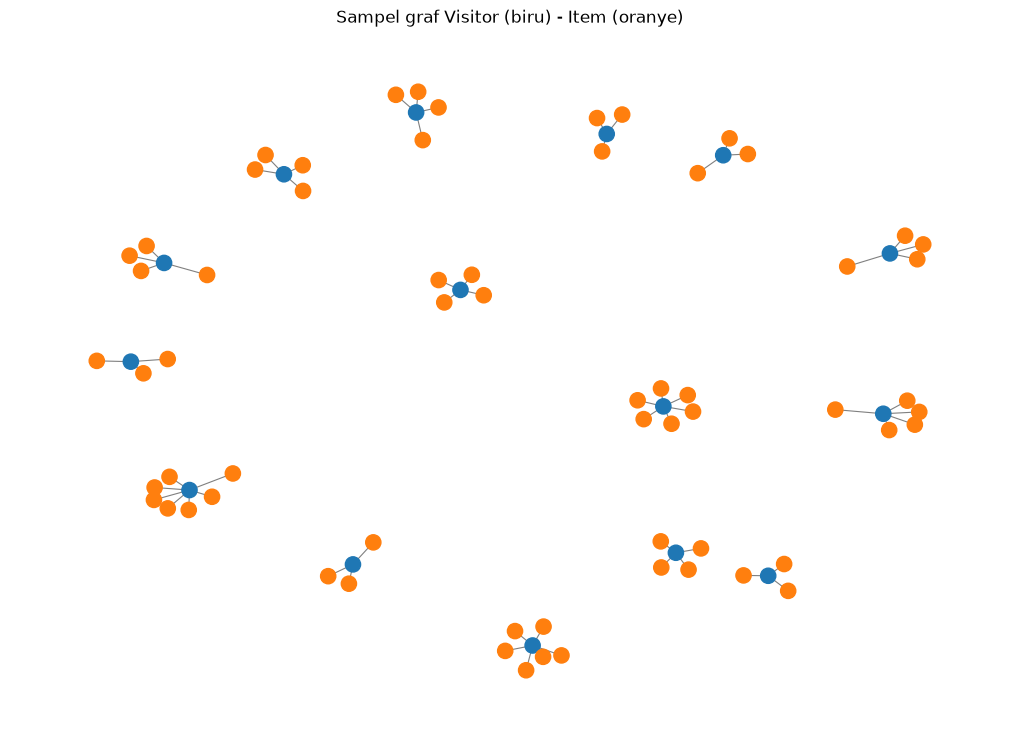

In [23]:
warna = ["tab:blue" if G.nodes[n]["jenis"] == "visitor" else "tab:orange"
         for n in G.nodes]

plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, node_color=warna, node_size=120, with_labels=False,
        edge_color="gray", width=0.8)
plt.title("Sampel graf Visitor (biru) - Item (oranye)")
plt.show()

In [26]:
# Matriks biner: 1 jika pernah berinteraksi
B = matriks.copy()
B.data = np.ones_like(B.data)
B_csc = B.tocsc()

# Item-Item: tiap visitor dengan k item menghasilkan k*(k-1)/2 pasangan item
k_v = np.diff(B.indptr).astype(np.int64)
pasangan_item = (k_v * (k_v - 1) // 2).sum()

# Visitor-Visitor: tiap item dengan m visitor menghasilkan m*(m-1)/2 pasangan visitor
m_i = np.diff(B_csc.indptr).astype(np.int64)
pasangan_visitor = (m_i * (m_i - 1) // 2).sum()

print("Perkiraan ukuran proyeksi (batas atas, sebelum dedup)")
print("Item-Item       : node =", B.shape[1], "| pasangan <=", pasangan_item)
print("Visitor-Visitor : node =", B.shape[0], "| pasangan <=", pasangan_visitor)

print("Visitor dengan >=2 item     :", (k_v >= 2).sum(), "(hanya mereka yang punya tetangga di Item-Item)")

Perkiraan ukuran proyeksi (batas atas, sebelum dedup)
Item-Item       : node = 169779 | pasangan <= 11339236
Visitor-Visitor : node = 658383 | pasangan <= 22334445
Visitor dengan >=2 item     : 132281 (hanya mereka yang punya tetangga di Item-Item)


menghitung cosine similarity untuk semua pasangan

In [27]:
from sklearn.preprocessing import normalize

X = normalize(B.T.tocsr().astype(np.float32), norm="l2")

S = X @ X.T
S.setdiag(0)
S.eliminate_zeros()

print("Shape:", S.shape)
print("Pasangan terisi (dua arah):", S.nnz)
print("Nilai terbesar:", S.max())

Shape: (169779, 169779)
Pasangan terisi (dua arah): 20843030
Nilai terbesar: 1.0


7a

mengambil 5 teratas cosine simmilarity paling tinggi dari suatu item

In [28]:
jumlah_visitor_item = np.diff(B_csc.indptr)
kandidat_item = np.where((jumlah_visitor_item >= 20) & (jumlah_visitor_item <= 50))[0]
rng = np.random.default_rng(42)
acuan = int(rng.choice(kandidat_item))

item_asli = item_ids.cat.categories
print("Item acuan:", item_asli[acuan], "| jumlah visitor:", jumlah_visitor_item[acuan])

baris_s = S.getrow(acuan).toarray().ravel()
top5 = np.argsort(-baris_s)[:5]
for idx in top5:
    print(item_asli[idx], round(float(baris_s[idx]), 4))

Item acuan: 44549 | jumlah visitor: 22
371823 0.2326
373425 0.2132
301512 0.2132
276181 0.1396
352783 0.1231


7b

In [29]:
pasangan = [
    {"a": int(item_asli[acuan]),
     "b": int(item_asli[idx]),
     "skor": float(baris_s[idx])}
    for idx in top5
]
print(pasangan)

query_tulis = """
UNWIND $pasangan AS p
MATCH (a:Item {itemId: p.a})
MATCH (b:Item {itemId: p.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.cosine = p.skor
"""

driver.execute_query(query_tulis, pasangan=pasangan, database_="neo4j")
print("Selesai menulis", len(pasangan), "relasi SIMILAR_TO")

[{'a': 44549, 'b': 371823, 'skor': 0.23262105882167816}, {'a': 44549, 'b': 373425, 'skor': 0.21320071816444397}, {'a': 44549, 'b': 301512, 'skor': 0.21320071816444397}, {'a': 44549, 'b': 276181, 'skor': 0.1395726352930069}, {'a': 44549, 'b': 352783, 'skor': 0.12309148907661438}]
Selesai menulis 5 relasi SIMILAR_TO


8

![Screenshot 2026-10-21 113551.png](<attachment:Screenshot 2026-10-21 113551.png>)
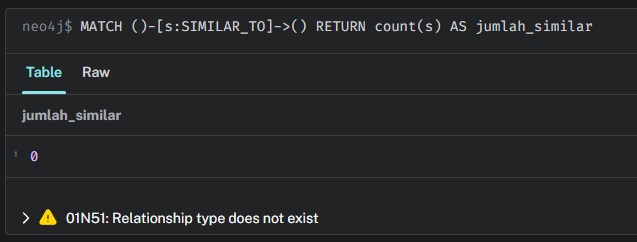

MATCH (a:Item)-[s:SIMILAR_TO]->(b:Item)
RETURN a, s, b

![Screenshot 2026-10-21 113620.png](<attachment:Screenshot 2026-10-21 113620.png>)
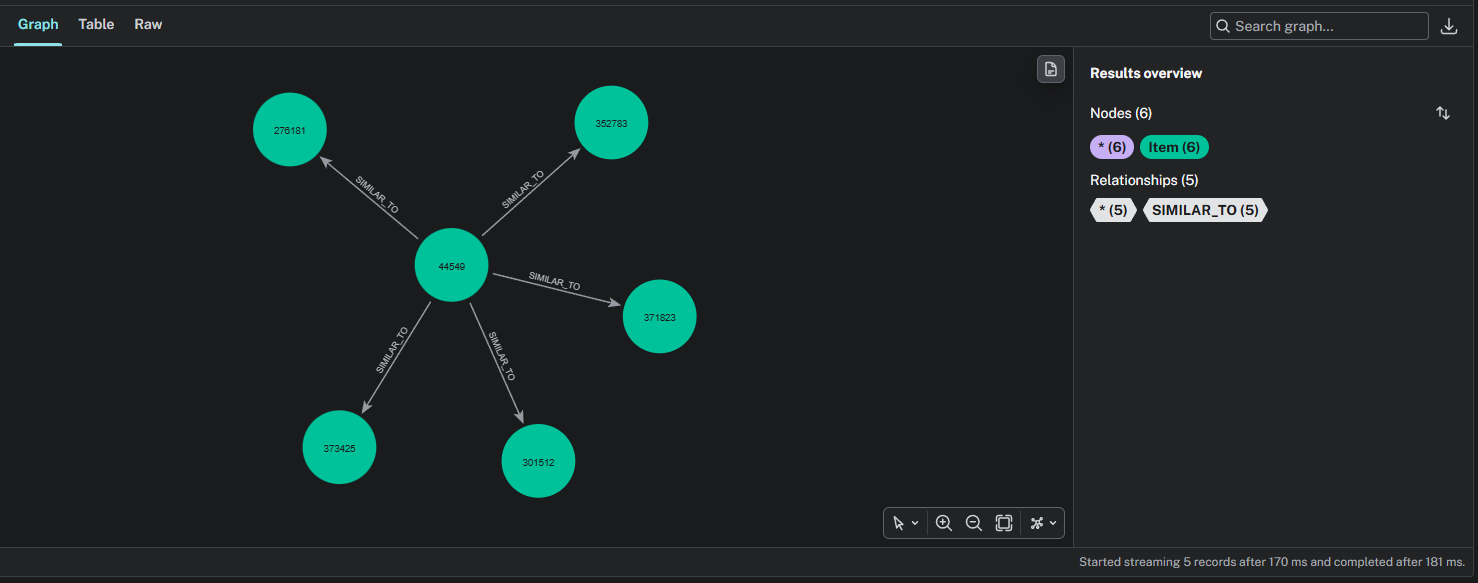

## 2.2

In [30]:
p2 = pd.read_csv("data/events_p2.csv")

visitor_asli = visitor_ids.cat.categories   # nomor -> visitorId asli
item_asli    = item_ids.cat.categories      # nomor -> itemId asli

p2 = p2[p2["itemid"].isin(item_asli) & p2["visitorid"].isin(visitor_asli)]
relevan_per_visitor = p2.groupby("visitorid")["itemid"].apply(set)

idx_visitor = pd.Series(np.arange(len(visitor_asli)), index=visitor_asli)

def item_p1_user(v):
    i = int(idx_visitor[v])
    return {int(item_asli[k]) for k in B.indices[B.indptr[i]:B.indptr[i+1]]}

relevan_baru = {}
for v, s in relevan_per_visitor.items():
    if item_per_visitor[idx_visitor[v]] >= 3:
        baru = {int(x) for x in s} - item_p1_user(v)
        if baru:
            relevan_baru[int(v)] = baru

kandidat = sorted(relevan_baru.keys())
rng = np.random.default_rng(42)
user_id  = int(rng.choice(kandidat))
user_idx = int(idx_visitor[user_id])
item_p1  = sorted(item_p1_user(user_id))
kunci    = sorted(relevan_baru[user_id])

print("Jumlah kandidat user:", len(kandidat))
print("User terpilih       :", user_id)
print("Item di P1          :", item_p1)
print("Kunci jawaban (P2)  :", kunci)

Jumlah kandidat user: 2304
User terpilih       : 126107
Item di P1          : [198400, 346429, 396619]
Kunci jawaban (P2)  : [426031]


1a + 1b

In [31]:
k = 5
idx_item = pd.Series(np.arange(len(item_asli)), index=item_asli)

skor = {}          # itemId kandidat -> total skor
detail = {}        # untuk dokumentasi: tetangga tiap item user

for it in item_p1:
    baris = S.getrow(int(idx_item[it]))
    kol, nilai = baris.indices, baris.data
    # Urutkan nilai terbesar dulu; kalau seri, node dengan nomor kecil dulu (deterministik)
    urut = np.lexsort((kol, -nilai))[:k]
    detail[it] = [(int(item_asli[kol[j]]), round(float(nilai[j]), 4)) for j in urut]
    for j in urut:
        kandidat_id = int(item_asli[kol[j]])
        skor[kandidat_id] = skor.get(kandidat_id, 0.0) + float(nilai[j])

# Buang item yang sudah disentuh user di P1
for it in item_p1:
    skor.pop(it, None)

# Urutkan: skor terbesar dulu, seri diurutkan berdasarkan itemId
ranking = sorted(skor.items(), key=lambda x: (-x[1], x[0]))

print("User:", user_id, "| Item di P1:", item_p1)
print("\nTetangga (k=5) tiap item user:")
for it, tt in detail.items():
    print(" ", it, "->", tt)

print("\nRanking kandidat (top 5 untuk evaluasi):")
for r, (it, s) in enumerate(ranking[:5], start=1):
    print(f"  {r}. {it}  skor={s:.4f}")

print("\n3 item yang diiklankan:", [it for it, _ in ranking[:3]])

User: 126107 | Item di P1: [198400, 346429, 396619]

Tetangga (k=5) tiap item user:
  198400 -> [(414402, 0.2513), (455473, 0.2341), (90210, 0.2052), (68390, 0.1947), (149588, 0.1622)]
  346429 -> [(272976, 0.169), (396619, 0.1638), (284000, 0.1423), (93101, 0.141), (4305, 0.1085)]
  396619 -> [(346429, 0.1638), (275406, 0.1599), (272976, 0.09), (41191, 0.0854), (51822, 0.0854)]

Ranking kandidat (top 5 untuk evaluasi):
  1. 272976  skor=0.2590
  2. 414402  skor=0.2513
  3. 455473  skor=0.2341
  4. 90210  skor=0.2052
  5. 68390  skor=0.1947

3 item yang diiklankan: [272976, 414402, 455473]


2a + 2b

In [32]:
relevan = set(kunci)
top5 = [it for it, _ in ranking[:5]]

hit5 = 1 if any(it in relevan for it in top5) else 0

dcg = sum(1 / np.log2(pos + 1)
          for pos, it in enumerate(top5, start=1) if it in relevan)
n_ideal = min(len(relevan), 5)
idcg = sum(1 / np.log2(pos + 1) for pos in range(1, n_ideal + 1))
ndcg5 = dcg / idcg

print("Hit@5  :", hit5)
print("NDCG@5 :", round(ndcg5, 4))

Hit@5  : 0
NDCG@5 : 0.0
